# Pre-entrega 3 · Modelos de clasificación: ¿quién termina en el Top 4 de la Premier League?

**Proyecto:** Premier League 1993–2026 · EnergIA Digital – Data Science

**Pregunta:** a partir de lo que se sabe *antes* de que empiece la temporada (cómo le fue al equipo en las temporadas anteriores), ¿podemos predecir si termina entre los 4 primeros (zona de Champions League)?

**Recorrido (de la EDA a la selección del modelo):**
1. Tabla equipo-temporada reconstruida y variable objetivo
2. Variables sin fuga de información y partición temporal train/test
3. Validación cruzada temporal (y por qué no la mezclada)
4. Comparación de modelos contra un baseline
5. Optimización de hiperparámetros (`GridSearchCV`) y control de overfitting
6. Evaluación final en test (una sola vez)
7. Interpretación, rol del DT británico/extranjero y regresión complementaria

**Parte II (objetivo del grupo):** campeones con DT británico vs. extranjero, modelo de campeón y proyección a 10 años con escenarios y backtest (secciones 10 a 13).

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import cross_val_score, GridSearchCV, validation_curve, StratifiedKFold
from sklearn.metrics import (roc_auc_score, f1_score, precision_score, recall_score, accuracy_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve,
                             mean_absolute_error, mean_squared_error, r2_score)
from sklearn.inspection import permutation_importance

SEED = 42
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#8a8a85"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": .25, "figure.dpi": 100, "axes.titleweight": "bold"})

# La tabla se genera con:  python src/construir_tabla_temporadas.py
RUTA = next(p for p in ["../data/processed/tabla_temporadas.csv", "data/processed/tabla_temporadas.csv"] if os.path.exists(p))
tabla = pd.read_csv(RUTA)
print(tabla.shape)
tabla.head()

(664, 22)


,temp_inicio,equipo,partidos_jugados,puntos_totales,goles_favor,goles_contra,dif_gol,posicion,top4,prev_puntos,prev_posicion,prev_dif_gol,prev_goles_favor,prev_goles_contra,prev_top4,prev2_puntos,top4_ult3,ascendido,dt_inicio,dt_registrado,dt_britanico,temporada
0,1993,Manchester United,42,92,80,38,42,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,1,Alex Ferguson,1.0,1.0,1993-94
1,1993,Blackburn,42,84,63,36,27,2,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,1,DT No Registrado,0.0,NaN,1993-94
2,1993,Newcastle,42,77,82,41,41,3,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,1,DT No Registrado,0.0,NaN,1993-94
3,1993,Arsenal,42,71,53,28,25,4,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,1,George Graham,1.0,1.0,1993-94
4,1993,Leeds,42,70,65,39,26,5,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,1,DT No Registrado,0.0,NaN,1993-94


## 1. Datos y variable objetivo

Cada fila es un **equipo en una temporada** (664 filas, 1993/94–2025/26). Se reconstruyó la tabla de posiciones desde los CSV originales (`src/construir_tabla_temporadas.py`) por dos motivos:

- `on_bad_lines='skip'` en la unión de CSV descartaba **90 partidos** de 2003/04 y 2004/05; acá se recuperan los 12.704.
- La posición se calcula con el desempate oficial (puntos → diferencia de gol → goles a favor); si solo se ordena por puntos, hay empates en el 4.º puesto que dejan equipos Top 4 de más o de menos.

**Objetivo:** `top4 = 1` si el equipo terminó entre los 4 primeros. Es una aproximación a "clasificar a Champions" (los cupos reales dependen de otras competiciones), pero es un criterio objetivo y siempre hay exactamente 4 positivos por temporada.

In [2]:
print("Top 4 por temporada (debe ser 4):", tabla.groupby("temp_inicio")["top4"].sum().unique())
print("Partidos por equipo-temporada:", tabla["partidos_jugados"].value_counts().to_dict())
tabla[tabla.temp_inicio >= 2022].query("top4 == 1")[["temporada", "equipo", "puntos_totales", "posicion"]]

Top 4 por temporada (debe ser 4): [4]
Partidos por equipo-temporada: {38: 620, 42: 44}


,temporada,equipo,puntos_totales,posicion
584,2022-23,Manchester City,89,1
585,2022-23,Arsenal,84,2
586,2022-23,Manchester United,75,3
587,2022-23,Newcastle,71,4
604,2023-24,Manchester City,91,1
605,2023-24,Arsenal,89,2
606,2023-24,Liverpool,82,3
607,2023-24,Aston Villa,68,4
624,2024-25,Liverpool,84,1
625,2024-25,Arsenal,74,2


## 2. Variables sin fuga de información (*data leakage*)

La EDA original usaba `goles_favor`, `goles_contra` y `diferencia_gol` **de la misma temporada**. Esas variables se calculan con la temporada ya jugada, y con ellas la clasificación es casi una tautología (equipos con muchos puntos tienen buena diferencia de gol). El modelo no estaría prediciendo nada: estaría describiendo.

Acá usamos solo **información disponible antes de que empiece la temporada**:

| Variable | Qué es |
|---|---|
| `prev_puntos`, `prev_posicion`, `prev_dif_gol`, `prev_goles_favor`, `prev_goles_contra`, `prev_top4` | resultado de la temporada anterior |
| `prev2_puntos` | puntos de hace dos temporadas |
| `top4_ult3` | cuántas veces fue Top 4 en las últimas 3 temporadas |
| `ascendido` | 1 si no jugó la Premier la temporada anterior (no hay historial) |

Los faltantes (equipos ascendidos) se imputan con la mediana **dentro del `Pipeline`**, para que se calcule solo con datos de entrenamiento en cada fold.

In [3]:
FEATURES = ["prev_puntos", "prev_posicion", "prev_dif_gol", "prev_goles_favor", "prev_goles_contra",
            "prev_top4", "prev2_puntos", "top4_ult3", "ascendido"]

# Partición TEMPORAL: se entrena con el pasado y se testea con temporadas futuras
tabla = tabla[tabla.temp_inicio >= 2000].reset_index(drop=True)   # era Champions de 4 cupos y 20 equipos estable
train = tabla[tabla.temp_inicio <= 2021].reset_index(drop=True)   # 2000/01 – 2021/22
test  = tabla[tabla.temp_inicio >= 2022].reset_index(drop=True)   # 2022/23 – 2025/26

X_train, y_train = train[FEATURES], train["top4"]
X_test,  y_test  = test[FEATURES],  test["top4"]
print(f"train: {len(train)} filas, {y_train.sum()} Top 4 ({y_train.mean():.0%})")
print(f"test : {len(test)} filas, {y_test.sum()} Top 4 ({y_test.mean():.0%})")

train: 440 filas, 88 Top 4 (20%)
test : 80 filas, 16 Top 4 (20%)


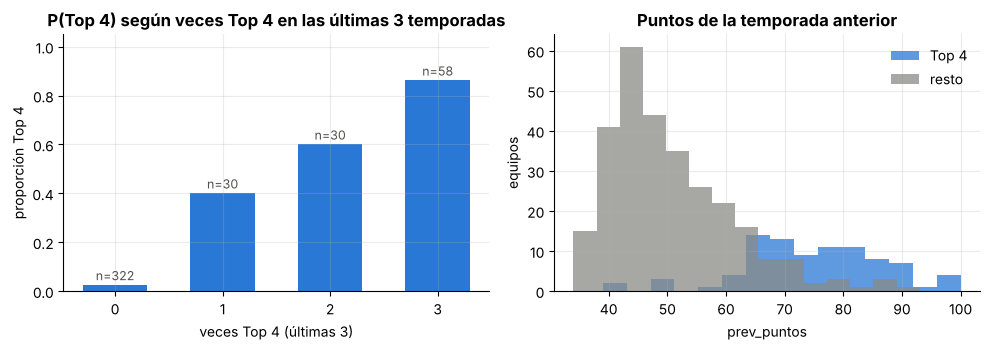

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
tasa = train.groupby("top4_ult3")["top4"].agg(["mean", "size"])
axes[0].bar(tasa.index, tasa["mean"], color=AZUL, width=.6)
for k, (m, n) in tasa.iterrows():
    axes[0].text(k, m + .02, f"n={int(n)}", ha="center", fontsize=9, color="#52514e")
axes[0].set(title="P(Top 4) según veces Top 4 en las últimas 3 temporadas", xlabel="veces Top 4 (últimas 3)", ylabel="proporción Top 4", ylim=(0, 1.05))
axes[0].set_xticks(tasa.index)

for v, c, lab in [(1, AZUL, "Top 4"), (0, GRIS, "resto")]:
    axes[1].hist(train.loc[train.top4 == v, "prev_puntos"].dropna(), bins=15, alpha=.75, color=c, label=lab)
axes[1].set(title="Puntos de la temporada anterior", xlabel="prev_puntos", ylabel="equipos")
axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()

El historial reciente separa bien: un equipo que fue Top 4 en las últimas tres temporadas tiene mucha más probabilidad de repetir. Era esperable, y por eso el baseline "a ciegas" no alcanza como vara de comparación: se compara también contra una regla simple basada en el pasado.

## 3. Validación cruzada: temporal, no mezclada

Con `KFold`/`StratifiedKFold` mezclando filas, un fold de validación puede tener la temporada 2015 mientras el entrenamiento incluye 2016 y 2017. Eso es entrenar con el futuro. En este dataset la diferencia de AUC es chica (el historial de cada equipo cambia lento), pero la mezclada no responde a la pregunta real —predecir una temporada que todavía no pasó— y en otros problemas puede inflar mucho el resultado. Usamos **bloques de temporadas con ventana expansiva** (como `TimeSeriesSplit`, pero agrupando por temporada porque cada una tiene 20 filas):

| Fold | Entrena con | Valida en |
|---|---|---|
| 1 | 2000/01–2009/10 | 2010/11–2012/13 |
| 2 | 2000/01–2012/13 | 2013/14–2015/16 |
| 3 | 2000/01–2015/16 | 2016/17–2018/19 |
| 4 | 2000/01–2018/19 | 2019/20–2021/22 |

In [5]:
def folds_temporales(df, bloques=((2010, 2012), (2013, 2015), (2016, 2018), (2019, 2021))):
    # lista de (idx_train, idx_val): se entrena con todo lo anterior al bloque
    out = []
    for ini, fin in bloques:
        tr = df.index[df.temp_inicio < ini].to_numpy()
        va = df.index[(df.temp_inicio >= ini) & (df.temp_inicio <= fin)].to_numpy()
        out.append((tr, va))
    return out

CV = folds_temporales(train)
for i, (tr, va) in enumerate(CV, 1):
    print(f"fold {i}: train={len(tr)}  val={len(va)}  Top4 val={int(y_train.iloc[va].sum())}")

# Métrica de selección: ROC-AUC (hay 20% de positivos; accuracy engaña: decir siempre "no" da 80%)
def pipe(modelo, escalar=True):
    pasos = [("imp", SimpleImputer(strategy="median"))]
    if escalar: pasos.append(("sc", StandardScaler()))
    return Pipeline(pasos + [("m", modelo)])

# ¿Cuánto optimismo introduce la CV mezclada?
rf = pipe(RandomForestClassifier(n_estimators=200, min_samples_leaf=3, random_state=SEED), escalar=False)
auc_temporal = cross_val_score(rf, X_train, y_train, cv=CV, scoring="roc_auc")
auc_mezclada = cross_val_score(rf, X_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring="roc_auc")
print(f"\nRandom Forest  AUC CV temporal: {auc_temporal.mean():.3f}   |   AUC CV mezclada: {auc_mezclada.mean():.3f}")

fold 1: train=200  val=60  Top4 val=12
fold 2: train=260  val=60  Top4 val=12
fold 3: train=320  val=60  Top4 val=12
fold 4: train=380  val=60  Top4 val=12

Random Forest  AUC CV temporal: 0.938   |   AUC CV mezclada: 0.943


## 4. Comparación de modelos (hiperparámetros por defecto)

Se compara contra un `DummyClassifier` (baseline) y contra una **regla simple**: "Top 4 si lo fue la temporada anterior". Todo dentro de un `Pipeline` (imputación y escalado se reajustan en cada fold).

In [6]:
modelos = {
    "Dummy (baseline)":     pipe(DummyClassifier(strategy="prior")),
    "Regresión logística":  pipe(LogisticRegression(max_iter=1000, class_weight="balanced")),
    "KNN":                  pipe(KNeighborsClassifier()),
    "Árbol de decisión":    pipe(DecisionTreeClassifier(random_state=SEED), escalar=False),
    "Random Forest":        pipe(RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=SEED), escalar=False),
    "Gradient Boosting":    pipe(GradientBoostingClassifier(random_state=SEED), escalar=False),
}
filas = []
for nombre, m in modelos.items():
    s = cross_val_score(m, X_train, y_train, cv=CV, scoring="roc_auc")
    filas.append({"modelo": nombre, "AUC CV (media)": s.mean(), "desvío entre folds": s.std()})

# Regla simple: la probabilidad es 1 si fue Top 4 el año anterior
regla = [roc_auc_score(y_train.iloc[va], train["prev_top4"].fillna(0).iloc[va]) for _, va in CV]
filas.append({"modelo": "Regla: Top 4 el año anterior", "AUC CV (media)": np.mean(regla), "desvío entre folds": np.std(regla)})

res_base = pd.DataFrame(filas).set_index("modelo").round(3).sort_values("AUC CV (media)", ascending=False)
res_base

,AUC CV (media),desvío entre folds
modelo,,
Regresión logística,0.950,0.030
Gradient Boosting,0.929,0.029
Random Forest,0.926,0.040
KNN,0.919,0.033
Árbol de decisión,0.857,0.019
Regla: Top 4 el año anterior,0.831,0.043
Dummy (baseline),0.500,0.000


## 5. Optimización de hiperparámetros y overfitting

Se ajusta cada modelo con `GridSearchCV` usando **la misma CV temporal** y `roc_auc`. Después se compara contra su versión sin optimizar.

In [7]:
grillas = {
    "Regresión logística": (pipe(LogisticRegression(max_iter=1000, class_weight="balanced")),
                            {"m__C": [0.01, 0.1, 1, 10]}),
    "KNN": (pipe(KNeighborsClassifier()),
            {"m__n_neighbors": [5, 15, 25, 35], "m__weights": ["uniform", "distance"]}),
    "Árbol de decisión": (pipe(DecisionTreeClassifier(class_weight="balanced", random_state=SEED), escalar=False),
                          {"m__max_depth": [2, 3, 4, 6], "m__min_samples_leaf": [5, 10, 20]}),
    "Random Forest": (pipe(RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=SEED), escalar=False),
                      {"m__max_depth": [3, 5, None], "m__min_samples_leaf": [1, 5, 10]}),
    "Gradient Boosting": (pipe(GradientBoostingClassifier(random_state=SEED), escalar=False),
                          {"m__n_estimators": [50, 100, 200], "m__max_depth": [1, 2, 3], "m__learning_rate": [0.03, 0.1]}),
}
optimizados, filas = {}, []
for nombre, (p, g) in grillas.items():
    gs = GridSearchCV(p, g, cv=CV, scoring="roc_auc", n_jobs=-1).fit(X_train, y_train)
    optimizados[nombre] = gs.best_estimator_
    filas.append({"modelo": nombre, "AUC CV sin optimizar": res_base.loc[nombre, "AUC CV (media)"],
                  "AUC CV optimizado": gs.best_score_,
                  "mejores parámetros": {k.replace("m__", ""): v for k, v in gs.best_params_.items()}})
res_opt = pd.DataFrame(filas).set_index("modelo")
res_opt["AUC CV sin optimizar"] = res_opt["AUC CV sin optimizar"].round(3)
res_opt["AUC CV optimizado"] = res_opt["AUC CV optimizado"].round(3)
res_opt

,AUC CV sin optimizar,AUC CV optimizado,mejores parámetros
modelo,,,
Regresión logística,0.950,0.950,{'C': 1}
KNN,0.919,0.946,"{'n_neighbors': 35, 'weights': 'distance'}"
Árbol de decisión,0.857,0.925,"{'max_depth': 6, 'min_samples_leaf': 10}"
Random Forest,0.926,0.940,"{'max_depth': None, 'min_samples_leaf': 10}"
Gradient Boosting,0.929,0.934,"{'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 50}"


La optimización ayuda sobre todo a los modelos que tienden a sobreajustar (árbol: 0.857 → 0.925, KNN: 0.919 → 0.946); en la regresión logística y en Gradient Boosting casi no cambia nada.

**Aviso:** el AUC de CV del modelo optimizado es algo optimista (se eligió el mejor entre varias combinaciones mirando esos mismos folds). La estimación honesta es la del test, que se usa una sola vez más abajo.

### Curva de validación: dónde empieza el overfitting

Para el árbol, se grafica AUC de entrenamiento vs. validación al crecer `max_depth`. Cuando la curva de train sigue subiendo y la de validación se estanca o cae, el modelo empieza a memorizar.

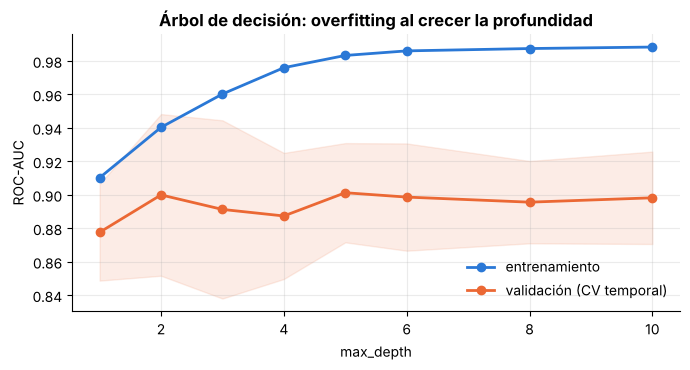

In [8]:
profs = [1, 2, 3, 4, 5, 6, 8, 10]
arbol = pipe(DecisionTreeClassifier(class_weight="balanced", min_samples_leaf=5, random_state=SEED), escalar=False)
tr_sc, va_sc = validation_curve(arbol, X_train, y_train, param_name="m__max_depth", param_range=profs,
                                cv=CV, scoring="roc_auc")
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(profs, tr_sc.mean(1), "-o", color=AZUL, lw=2, label="entrenamiento")
ax.plot(profs, va_sc.mean(1), "-o", color=NARANJA, lw=2, label="validación (CV temporal)")
ax.fill_between(profs, va_sc.mean(1) - va_sc.std(1), va_sc.mean(1) + va_sc.std(1), color=NARANJA, alpha=.12)
ax.set(title="Árbol de decisión: overfitting al crecer la profundidad", xlabel="max_depth", ylabel="ROC-AUC")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

## 6. Evaluación final en test (una sola vez)

Los modelos ya están elegidos con train. Se reajustan con todo el train y se evalúan en **2022/23–2025/26**, temporadas que no se usaron en ningún momento para decidir nada.

Con 80 filas y 16 positivos, el test es **chico**: una diferencia de un par de equipos mueve bastante las métricas. Hay que leerlo como orden de magnitud, no como un número exacto.

In [9]:
def evaluar(modelo, X, y, umbral=0.5):
    proba = modelo.predict_proba(X)[:, 1]
    pred = (proba >= umbral).astype(int)
    return {"AUC": roc_auc_score(y, proba), "F1": f1_score(y, pred), "precisión": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred), "accuracy": accuracy_score(y, pred)}, proba

a_evaluar = {"Dummy (baseline)": modelos["Dummy (baseline)"]}
for n in optimizados: a_evaluar[n + " (sin optimizar)"] = modelos[n]; a_evaluar[n + " (optimizado)"] = optimizados[n]

filas, probas = {}, {}
for n, m in a_evaluar.items():
    m.fit(X_train, y_train)
    filas[n], probas[n] = evaluar(m, X_test, y_test)
filas["Regla: Top 4 el año anterior"] = {"AUC": roc_auc_score(y_test, test["prev_top4"].fillna(0)),
    "F1": f1_score(y_test, test["prev_top4"].fillna(0)), "precisión": precision_score(y_test, test["prev_top4"].fillna(0)),
    "recall": recall_score(y_test, test["prev_top4"].fillna(0)), "accuracy": accuracy_score(y_test, test["prev_top4"].fillna(0))}
res_test = pd.DataFrame(filas).T.round(3).sort_values("AUC", ascending=False)
res_test

,AUC,F1,precisión,recall,accuracy
Random Forest (optimizado),0.855,0.600,0.500,0.750,0.800
Gradient Boosting (optimizado),0.847,0.621,0.692,0.562,0.862
KNN (sin optimizar),0.844,0.588,0.556,0.625,0.825
KNN (optimizado),0.844,0.545,0.529,0.562,0.812
Árbol de decisión (optimizado),0.835,0.553,0.419,0.812,0.738
Gradient Boosting (sin optimizar),0.834,0.500,0.450,0.562,0.775
Random Forest (sin optimizar),0.832,0.526,0.455,0.625,0.775
Regresión logística (sin optimizar),0.827,0.500,0.450,0.562,0.775
Regresión logística (optimizado),0.827,0.500,0.450,0.562,0.775
Árbol de decisión (sin optimizar),0.750,0.588,0.556,0.625,0.825


`accuracy` engaña: el Dummy que dice "nunca Top 4" ya saca ~80%. Por eso se mira AUC (calidad del ranking) y F1/recall (qué tan bien se encuentran los positivos).

### Mejor modelo: matriz de confusión y curva ROC

Modelo elegido por CV: Regresión logística (optimizado)


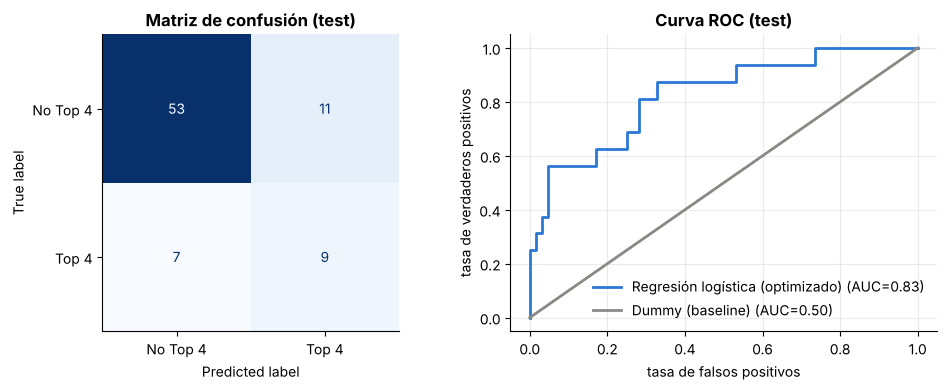

In [10]:
# El modelo se elige con la CV de train (no con el test, para no filtrar información del test)
mejor = res_opt["AUC CV optimizado"].idxmax() + " (optimizado)"
print("Modelo elegido por CV:", mejor)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
pred = (probas[mejor] >= .5).astype(int)
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["No Top 4", "Top 4"]).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Matriz de confusión (test)"); axes[0].grid(False)
for n, c in [(mejor, AZUL), ("Dummy (baseline)", GRIS)]:
    fpr, tpr, _ = roc_curve(y_test, probas[n])
    axes[1].plot(fpr, tpr, color=c, lw=2, label=f"{n} (AUC={roc_auc_score(y_test, probas[n]):.2f})")
axes[1].set(xlabel="tasa de falsos positivos", ylabel="tasa de verdaderos positivos")
axes[1].plot([0, 1], [0, 1], ls=":", color=GRIS); axes[1].set_title("Curva ROC (test)"); axes[1].legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

### Lectura por temporada: elegir los 4 con mayor probabilidad

Como cada temporada tiene exactamente 4 cupos, una forma natural de usar el modelo es **ordenar los 20 equipos por probabilidad y quedarse con los 4 primeros**. Esto evita depender del umbral 0.5.

In [11]:
t = test.assign(proba=probas[mejor])
t["rank_modelo"] = t.groupby("temp_inicio")["proba"].rank(ascending=False, method="first")
t["pred_top4"] = (t["rank_modelo"] <= 4).astype(int)
aciertos = t.groupby("temporada").apply(lambda d: int(((d.pred_top4 == 1) & (d.top4 == 1)).sum()))
print("Aciertos de 4 posibles por temporada:", aciertos.to_dict(), f"-> {aciertos.sum()}/16")
for temp, d in t.groupby("temporada"):
    print(f"\n{temp}  real: {', '.join(d[d.top4 == 1].sort_values('posicion').equipo)}")
    print(f"{'':7}modelo: {', '.join(d[d.pred_top4 == 1].sort_values('proba', ascending=False).equipo)}")

Aciertos de 4 posibles por temporada: {'2022-23': 1, '2023-24': 3, '2024-25': 3, '2025-26': 2} -> 9/16

2022-23  real: Manchester City, Arsenal, Manchester United, Newcastle
       modelo: Manchester City, Liverpool, Chelsea, Tottenham

2023-24  real: Manchester City, Arsenal, Liverpool, Aston Villa
       modelo: Manchester City, Liverpool, Arsenal, Newcastle

2024-25  real: Liverpool, Arsenal, Manchester City, Chelsea
       modelo: Manchester City, Arsenal, Liverpool, Newcastle

2025-26  real: Arsenal, Manchester City, Manchester United, Aston Villa
       modelo: Arsenal, Liverpool, Manchester City, Chelsea


## 7. Interpretación: ¿qué variables importan?

Importancia por permutación en test (cuánto cae el AUC al mezclar una variable). Es más confiable que `feature_importances_` del árbol, que favorece variables continuas.

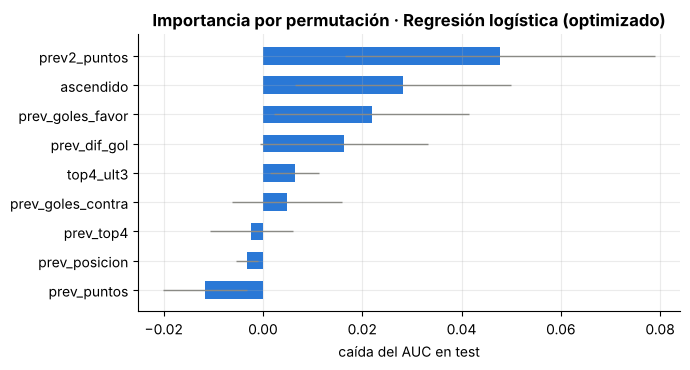

In [12]:
m_mejor = a_evaluar[mejor]
pi = permutation_importance(m_mejor, X_test, y_test, scoring="roc_auc", n_repeats=30, random_state=SEED)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values()
err = pd.Series(pi.importances_std, index=FEATURES)[imp.index]
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(imp.index, imp.values, xerr=err.values, color=AZUL, height=.6, error_kw={"ecolor": GRIS, "lw": 1})
ax.set(title=f"Importancia por permutación · {mejor}", xlabel="caída del AUC en test")
plt.tight_layout(); plt.show()

## 8. ¿Importa que el DT sea británico o extranjero?

Esta es la pregunta del proyecto. Antes hay un problema de datos que condiciona todo el análisis:

- En `dataset_final_modelo.csv`, los partidos con **"DT No Registrado"** quedaron con `es_britanico = 1` hasta 2004 y `= 0` desde 2005. Es un valor **imputado según el año**, no un dato real. Cualquier gráfico que lo use mostrará "los británicos dominaban antes" sin que sea evidencia.
- Por eso acá se usa `dt_britanico` **solo cuando el DT está registrado** (NaN en el resto), y se compara el modelo con y sin esa variable sobre las filas con DT conocido.

In [13]:
print("Cobertura del DT registrado al inicio de la temporada:")
print(f"  train {train.dt_registrado.mean():.0%}  |  test {test.dt_registrado.mean():.0%}")
reg = tabla[tabla.dt_registrado == 1]
print("\nTop 4 según nacionalidad del DT (solo DT registrado):")
print(reg.groupby("dt_britanico")["top4"].agg(["mean", "size"]).rename(index={0.0: "extranjero", 1.0: "británico"}, columns={"mean": "tasa Top 4", "size": "n"}).round(3))

Cobertura del DT registrado al inicio de la temporada:
  train 27%  |  test 32%

Top 4 según nacionalidad del DT (solo DT registrado):
              tasa Top 4   n
dt_britanico                
extranjero          0.74  96
británico           0.40  40


In [14]:
# Ablación sobre filas con DT registrado: ¿mejora el AUC agregar dt_britanico a las variables de historial?
reg_tr = train[train.dt_registrado == 1].reset_index(drop=True)
reg_te = test[test.dt_registrado == 1].reset_index(drop=True)
cv_reg = folds_temporales(reg_tr)
cv_reg = [(a, b) for a, b in cv_reg if reg_tr.top4.iloc[b].sum() > 0 and reg_tr.top4.iloc[a].sum() > 0]

def auc_cv(feats):
    m = pipe(LogisticRegression(max_iter=1000, class_weight="balanced"))
    return cross_val_score(m, reg_tr[feats], reg_tr.top4, cv=cv_reg, scoring="roc_auc").mean()

def auc_test(feats):
    m = pipe(LogisticRegression(max_iter=1000, class_weight="balanced")).fit(reg_tr[feats], reg_tr.top4)
    return roc_auc_score(reg_te.top4, m.predict_proba(reg_te[feats])[:, 1])

ablacion = pd.DataFrame({
    "solo historial": [auc_cv(FEATURES), auc_test(FEATURES)],
    "historial + dt_britanico": [auc_cv(FEATURES + ["dt_britanico"]), auc_test(FEATURES + ["dt_britanico"])],
}, index=["AUC CV", "AUC test"]).round(3)
print(f"Filas con DT registrado: train={len(reg_tr)}, test={len(reg_te)} (positivos en test: {int(reg_te.top4.sum())})")
ablacion

Filas con DT registrado: train=112, test=24 (positivos en test: 15)


,solo historial,historial + dt_britanico
AUC CV,0.727,0.744
AUC test,0.556,0.570


Si agregar `dt_britanico` no mueve el AUC (o lo mueve menos que el ruido entre folds), la nacionalidad del DT **no aporta información predictiva sobre el Top 4 más allá del historial del club**. Es coherente con la intuición: los clubes grandes contratan DTs extranjeros *y* clasifican, así que la nacionalidad está confundida con el tamaño del club. Con tan pocos casos de DT británico recientes (~4% de los registrados en test) tampoco hay poder estadístico para afirmar un efecto.

## 9. Complemento: regresión de los puntos de la temporada

Siguiendo la clase 15, se ajustan modelos de regresión para predecir `puntos_totales` con las mismas variables previas, con partición temporal y métricas MAE / RMSE / R². Baseline: predecir siempre los puntos de la temporada anterior.

In [15]:
def pipe_r(m, escalar=True):
    pasos = [("imp", SimpleImputer(strategy="median"))] + ([("sc", StandardScaler())] if escalar else [])
    return Pipeline(pasos + [("m", m)])

yr_tr, yr_te = train["puntos_totales"], test["puntos_totales"]
reg_modelos = {
    "Ridge":             pipe_r(Ridge(alpha=10)),
    "Random Forest":     pipe_r(RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=SEED), escalar=False),
    "Gradient Boosting": pipe_r(GradientBoostingRegressor(n_estimators=100, max_depth=2, learning_rate=0.05, random_state=SEED), escalar=False),
}
filas = {}
base = test["prev_puntos"].fillna(yr_tr.median())
filas["Baseline: puntos del año anterior"] = {"MAE": mean_absolute_error(yr_te, base), "RMSE": mean_squared_error(yr_te, base) ** .5, "R²": r2_score(yr_te, base)}
for n, m in reg_modelos.items():
    m.fit(X_train, yr_tr); p = m.predict(X_test)
    filas[n] = {"MAE": mean_absolute_error(yr_te, p), "RMSE": mean_squared_error(yr_te, p) ** .5, "R²": r2_score(yr_te, p)}
res_reg = pd.DataFrame(filas).T.round(2)
res_reg

,MAE,RMSE,R²
Baseline: puntos del año anterior,12.31,15.15,0.28
Ridge,10.66,12.95,0.47
Random Forest,11.03,13.34,0.44
Gradient Boosting,10.98,13.21,0.45


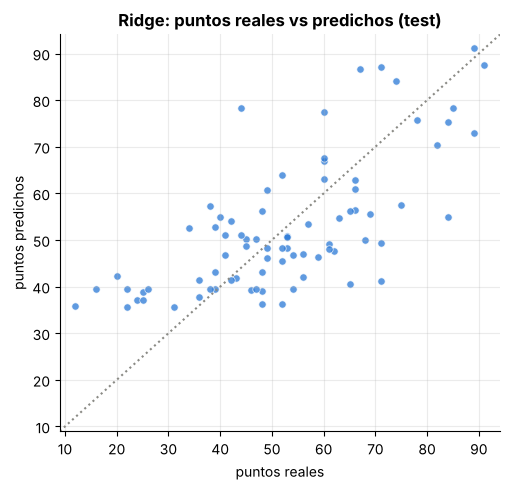

In [16]:
mejor_reg = res_reg.drop(index="Baseline: puntos del año anterior")["MAE"].idxmin()
pred_r = reg_modelos[mejor_reg].predict(X_test)
fig, ax = plt.subplots(figsize=(5.2, 5))
ax.scatter(yr_te, pred_r, s=28, color=AZUL, alpha=.75, edgecolor="white", linewidth=.6)
lim = [min(yr_te.min(), pred_r.min()) - 3, max(yr_te.max(), pred_r.max()) + 3]
ax.plot(lim, lim, ls=":", color=GRIS)
ax.set(title=f"{mejor_reg}: puntos reales vs predichos (test)", xlabel="puntos reales", ylabel="puntos predichos", xlim=lim, ylim=lim)
plt.tight_layout(); plt.show()

# PARTE II · El objetivo del grupo: DT británicos vs. extranjeros entre los campeones

Hasta acá se resolvió el problema de clasificación "¿Top 4?" con muchos casos (80 positivos en train). El objetivo que definió el grupo es más específico: **estimar, para los próximos 10 años, cuántos campeones tendrán un DT local (británico) y cuántos uno extranjero.**

Esto se divide en tres preguntas distintas, que conviene no mezclar:

1. **¿Quién campeona?** Clasificación con objetivo `campeon` (1 por temporada). Es la parte que se puede modelar con ML.
2. **¿Cómo evolucionó la nacionalidad del DT campeón?** Descripción histórica (33 campeones).
3. **¿Cuántos serían británicos en los próximos 10 años?** Extrapolación. Nadie puede saber hoy quién será DT del campeón de 2030, así que se presenta como **escenarios con incertidumbre** y se **valida con un backtest** (¿habría funcionado esta misma extrapolación en el pasado?).

## 10. Los 33 campeones y la nacionalidad de su DT

En `dataset_final_modelo.csv` 3 campeones aparecen con "DT No Registrado". Se completan a mano con información pública y se marcan en la columna `fuente` para que sea fácil revisarlos. "Británico" incluye a escoceses (Ferguson, Dalglish), igual que en el resto del proyecto.

In [17]:
completa = pd.read_csv(RUTA)
camp = completa[completa.posicion == 1][["temporada", "temp_inicio", "equipo", "puntos_totales", "dt_inicio", "dt_registrado", "dt_britanico"]].copy()

# Completado manual de los 3 campeones con DT "No Registrado" (verificar con el grupo)
COMPLETADOS = {"1994-95": ("Kenny Dalglish", 1),     # Blackburn, escocés
               "2014-15": ("José Mourinho", 0),      # Chelsea, portugués
               "2015-16": ("Claudio Ranieri", 0)}    # Leicester, italiano
camp["fuente"] = np.where(camp.dt_registrado == 1, "dataset", "completado a mano")
for temp, (dt, brit) in COMPLETADOS.items():
    m = camp.temporada == temp
    camp.loc[m, ["dt_inicio", "dt_britanico"]] = [dt, brit]
camp["dt_britanico"] = camp["dt_britanico"].astype(int)
camp["origen"] = np.where(camp.dt_britanico == 1, "británico", "extranjero")
camp = camp.reset_index(drop=True)

print(f"{len(camp)} campeones | británicos: {(camp.dt_britanico == 1).sum()} | extranjeros: {(camp.dt_britanico == 0).sum()}")
camp[["temporada", "equipo", "dt_inicio", "origen", "fuente"]].tail(14)

33 campeones | británicos: 13 | extranjeros: 20


,temporada,equipo,dt_inicio,origen,fuente
19,2012-13,Manchester United,Alex Ferguson,británico,dataset
20,2013-14,Manchester City,Manuel Pellegrini,extranjero,dataset
21,2014-15,Chelsea,José Mourinho,extranjero,completado a mano
22,2015-16,Leicester,Claudio Ranieri,extranjero,completado a mano
23,2016-17,Chelsea,Antonio Conte,extranjero,dataset
24,2017-18,Manchester City,Pep Guardiola,extranjero,dataset
25,2018-19,Manchester City,Pep Guardiola,extranjero,dataset
26,2019-20,Liverpool,Jurgen Klopp,extranjero,dataset
27,2020-21,Manchester City,Pep Guardiola,extranjero,dataset
28,2021-22,Manchester City,Pep Guardiola,extranjero,dataset


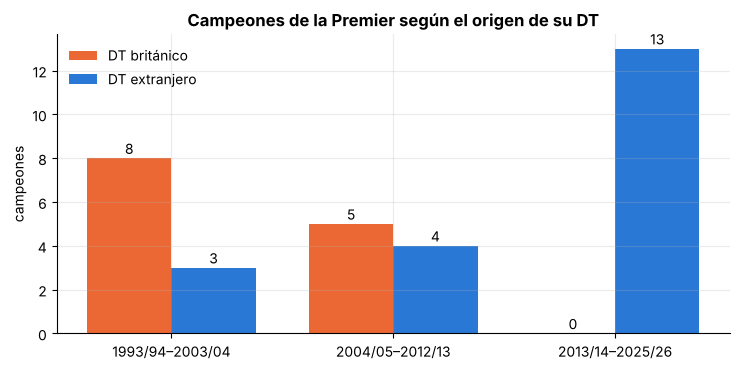

origen,británico,extranjero,temporadas,% británico
era,,,,
1993/94–2003/04,8,3,11,73.0
2004/05–2012/13,5,4,9,56.0
2013/14–2025/26,0,13,13,0.0


In [18]:
bins = [1992, 2003, 2012, 2025]
etiquetas = ["1993/94–2003/04", "2004/05–2012/13", "2013/14–2025/26"]
camp["era"] = pd.cut(camp.temp_inicio, bins=bins, labels=etiquetas)
tab = camp.groupby(["era", "origen"], observed=False).size().unstack(fill_value=0)[["británico", "extranjero"]]
tab["temporadas"] = tab.sum(axis=1)
tab["% británico"] = (100 * tab["británico"] / tab["temporadas"]).round(0)

fig, ax = plt.subplots(figsize=(7.5, 3.8))
x = np.arange(len(tab)); w = .38
ax.bar(x - w/2, tab["británico"], w, color=NARANJA, label="DT británico")
ax.bar(x + w/2, tab["extranjero"], w, color=AZUL, label="DT extranjero")
for xi, (b, e) in enumerate(zip(tab["británico"], tab["extranjero"])):
    ax.text(xi - w/2, b + .2, str(b), ha="center", fontsize=10); ax.text(xi + w/2, e + .2, str(e), ha="center", fontsize=10)
ax.set_xticks(x); ax.set_xticklabels(tab.index); ax.set(title="Campeones de la Premier según el origen de su DT", ylabel="campeones")
ax.legend(frameon=False); plt.tight_layout(); plt.show()
tab

Hay un **quiebre estructural**: con Ferguson los británicos ganaban la mayoría de los títulos; desde 2013/14 no ganó ninguno. Eso condiciona todo lo que sigue: un promedio de los 33 años no describe la situación actual.

## 11. ¿Quién campeona? Clasificación con objetivo `campeon`

Mismas variables previas, misma partición temporal y misma CV que en la Parte I. Hay solo 22 campeones en train (uno por temporada), así que no se hace búsqueda de hiperparámetros agresiva y se evalúa **por ranking**: cada temporada se ordenan los 20 equipos por probabilidad de ser campeón y se mira si el campeón real quedó primero (o entre los 3 primeros). Vara de comparación: la regla "campeona el que más puntos hizo la temporada anterior".

In [19]:
train["campeon"] = (train.posicion == 1).astype(int); test["campeon"] = (test.posicion == 1).astype(int)
yc_tr, yc_te = train["campeon"], test["campeon"]

modelos_c = {
    "Dummy (baseline)":    pipe(DummyClassifier(strategy="prior")),
    "Regresión logística": pipe(LogisticRegression(C=0.3, max_iter=1000, class_weight="balanced")),
    "Random Forest":       pipe(RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced", random_state=SEED), escalar=False),
    "Gradient Boosting":   pipe(GradientBoostingClassifier(n_estimators=100, max_depth=2, learning_rate=0.05, random_state=SEED), escalar=False),
}
filas = []
for n, m in modelos_c.items():
    s = cross_val_score(m, X_train, yc_tr, cv=CV, scoring="roc_auc")
    filas.append({"modelo": n, "AUC CV": s.mean(), "desvío": s.std()})
regla = [roc_auc_score(yc_tr.iloc[va], train["prev_puntos"].fillna(0).iloc[va]) for _, va in CV]
filas.append({"modelo": "Regla: más puntos el año anterior", "AUC CV": np.mean(regla), "desvío": np.std(regla)})
res_c = pd.DataFrame(filas).set_index("modelo").round(3).sort_values("AUC CV", ascending=False)
res_c

,AUC CV,desvío
modelo,,
Regla: más puntos el año anterior,0.875,0.099
Regresión logística,0.871,0.107
Gradient Boosting,0.865,0.088
Random Forest,0.857,0.114
Dummy (baseline),0.500,0.000


In [20]:
# Elección por CV (no por test) y evaluación única en test, por ranking dentro de cada temporada
mejor_c = res_c.drop(index="Regla: más puntos el año anterior").index[0]
print("Modelo elegido por CV:", mejor_c)
modelo_c = modelos_c[mejor_c].fit(X_train, yc_tr)

def aciertos_por_ranking(df, score):
    d = df.assign(score=score)
    d["rank"] = d.groupby("temp_inicio")["score"].rank(ascending=False, method="first")
    camp_rank = d[d.campeon == 1].set_index("temporada")["rank"].astype(int)
    return camp_rank

r_modelo = aciertos_por_ranking(test, modelo_c.predict_proba(X_test)[:, 1])
r_regla = aciertos_por_ranking(test, test["prev_puntos"].fillna(0).values)
comp = pd.DataFrame({"campeón real": test[test.campeon == 1].set_index("temporada")["equipo"],
                     "puesto del campeón según el modelo": r_modelo, "puesto según la regla": r_regla})
print(f"AUC test modelo: {roc_auc_score(yc_te, modelo_c.predict_proba(X_test)[:, 1]):.3f} | regla: {roc_auc_score(yc_te, test['prev_puntos'].fillna(0)):.3f}")
comp

Modelo elegido por CV: Regresión logística
AUC test modelo: 0.970 | regla: 0.954


,campeón real,puesto del campeón según el modelo,puesto según la regla
temporada,,,
2022-23,Manchester City,1,1
2023-24,Manchester City,1,1
2024-25,Liverpool,3,3
2025-26,Arsenal,1,2


En CV el modelo (AUC ≈ 0.87) **empata con la regla simple** "más puntos el año anterior" (≈ 0.875): el historial inmediato ya contiene casi toda la señal. En test (solo 4 campeones) el modelo puso al campeón primero en 3 de 4 temporadas y tercero en la restante (Liverpool 2024/25); la regla lo puso primero en 2 de 4. Con tan pocos casos eso no alcanza para decir que el modelo es mejor. Además hay campeones imposibles de anticipar con este historial (Leicester 2015/16 en el período de train).

**Esto no alcanza para responder la pregunta del grupo**: saber *qué club* es favorito no dice qué nacionalidad tendrá su DT dentro de 5 años. Para eso hace falta la proyección de la siguiente sección.

## 12. Proyección a 10 años (2026/27–2035/36): escenarios y backtest

**Método.** Sea `p` la probabilidad de que el campeón de un año tenga DT británico. Con `b` campeones británicos en `n` temporadas observadas, se estima `p` con un modelo Beta-Binomial (prior uniforme): la distribución de campeones británicos en 10 años sale de `Beta(1+b, 1+n−b)`. Esto da un valor esperado **y un intervalo**, no un número único.

**Qué ventana de historia usar** es la decisión clave, así que se muestran tres escenarios. Y como un modelo sin validación no vale, se hace un **backtest**: ¿qué habría predicho esta misma técnica en 2013, con datos hasta 2012/13, para los 10 años siguientes? Se compara con lo que pasó.

In [21]:
from scipy.stats import betabinom
H = 10  # años a proyectar

def proyectar(b, n, h=H):
    d = betabinom(h, 1 + b, 1 + n - b)
    return {"media": d.mean(), "p05": d.ppf(.05), "p95": d.ppf(.95), "p_estimada": (1 + b) / (2 + n)}

def contar(df):  # (británicos, temporadas)
    return int((df.dt_britanico == 1).sum()), len(df)

# --- Backtest: información hasta 2012/13 -> predicción 2013/14-2022/23 ---
pasado = camp[camp.temp_inicio <= 2012]; futuro = camp[(camp.temp_inicio >= 2013) & (camp.temp_inicio <= 2022)]
bt = {"Toda la historia (1993–2012)": proyectar(*contar(pasado)),
      "Últimos 10 años (2003–2012)": proyectar(*contar(pasado[pasado.temp_inicio >= 2003]))}
real_bt = int((futuro.dt_britanico == 1).sum())

# --- Proyección real: información hasta 2025/26 -> 2026/27-2035/36 ---
esc = {"Toda la historia (1993–2025)": proyectar(*contar(camp)),
       "Últimos 13 años (2013–2025)":  proyectar(*contar(camp[camp.temp_inicio >= 2013])),
       "Últimos 10 años (2016–2025)":  proyectar(*contar(camp[camp.temp_inicio >= 2016]))}

tabla_bt = pd.DataFrame(bt).T.round(1); tabla_bt["real 2013/14–2022/23"] = real_bt
tabla_es = pd.DataFrame(esc).T.round(1)
print("BACKTEST (¿cuántos campeones británicos en 10 años? esperado vs real)"); print(tabla_bt[["media", "p05", "p95", "real 2013/14–2022/23"]].to_string())
print("\nPROYECCIÓN 2026/27–2035/36 (campeones con DT británico, de 10)"); print(tabla_es[["media", "p05", "p95", "p_estimada"]].to_string())

BACKTEST (¿cuántos campeones británicos en 10 años? esperado vs real)
                              media  p05  p95  real 2013/14–2022/23
Toda la historia (1993–2012)    6.4  3.0  9.0                     0
Últimos 10 años (2003–2012)     5.0  2.0  8.0                     0

PROYECCIÓN 2026/27–2035/36 (campeones con DT británico, de 10)
                              media  p05  p95  p_estimada
Toda la historia (1993–2025)    4.0  1.0  7.0         0.4
Últimos 13 años (2013–2025)     0.7  0.0  3.0         0.1
Últimos 10 años (2016–2025)     0.8  0.0  3.0         0.1


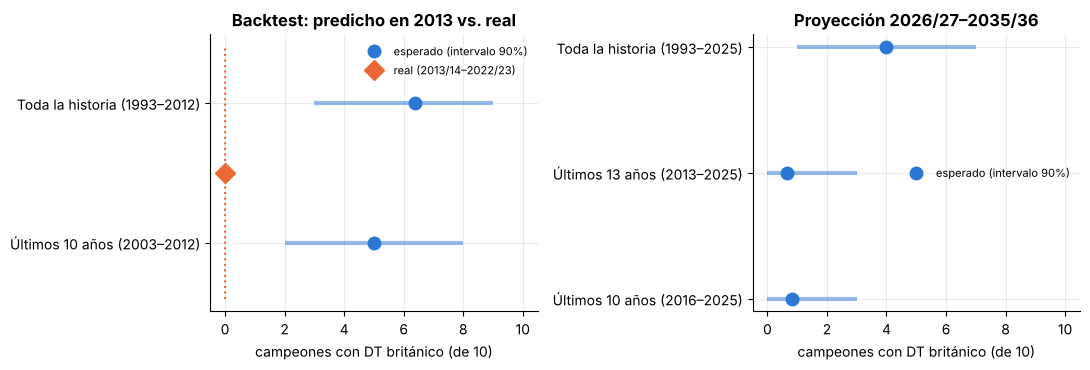

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
for ax, (tt, d, titulo) in zip(axes, [(tabla_bt, bt, "Backtest: predicho en 2013 vs. real"), (tabla_es, esc, "Proyección 2026/27–2035/36")]):
    y = np.arange(len(d))[::-1]
    for yi, (k, v) in zip(y, d.items()):
        ax.hlines(yi, v["p05"], v["p95"], color=AZUL, lw=3, alpha=.5)
        ax.plot(v["media"], yi, "o", color=AZUL, ms=9, label="esperado (intervalo 90%)" if yi == y[0] else None)
    ax.set_yticks(y); ax.set_yticklabels(list(d.keys())); ax.set(title=titulo, xlabel="campeones con DT británico (de 10)", xlim=(-.5, 10.5))
axes[0].plot(real_bt, np.mean(np.arange(2)), "D", color=NARANJA, ms=10, label="real (2013/14–2022/23)")
axes[0].vlines(real_bt, -.4, 1.4, color=NARANJA, lw=1.5, ls=":")
axes[0].legend(frameon=False, loc="upper right", fontsize=8); axes[1].legend(frameon=False, loc="center right", fontsize=8)
plt.tight_layout(); plt.show()

**Cómo leerlo**

- **El backtest falla**: usando historia hasta 2012/13, la técnica esperaba entre 5 y 6 campeones británicos en los 10 años siguientes y ocurrieron **0**, fuera del intervalo del 90%. Un promedio histórico no sirve cuando hay un cambio de régimen.
- **Para 2026–2036**, los escenarios van de **~0.7 (últimos 13 años) a ~4 (toda la historia)** campeones británicos de 10. Los escenarios con ventana reciente son los más defendibles porque el cambio de régimen ya lleva más de una década, pero **es una hipótesis, no un resultado**: nada en estos datos prueba que se mantenga.
- Lo que sí se puede afirmar con los datos: **los 13 últimos campeones tuvieron DT extranjero**, y el escenario razonable es que los DT británicos sean una minoría marcada (esperado menor a 1 de 10, con un intervalo del 90% de 0 a 3).

## 13. Conclusiones

**Parte I · Top 4 (clasificación con muchos casos)**
- Flujo completo: tabla reconstruida, variables sin fuga, partición y CV **temporales**, `Pipeline`, baseline, 5 modelos, `GridSearchCV` y curva de validación.
- Por CV temporal gana la **regresión logística** (AUC ≈ 0.95); en test baja a ≈ 0.83 (la regla "fue Top 4 el año anterior" cae a 0.69). Con 16 positivos en test, las diferencias entre modelos parecidos no son significativas. Se acertaron 9 de 16 cupos eligiendo los 4 más probables por temporada.
- El árbol sin límite de profundidad sobreajusta (AUC de entrenamiento ≈ 0.99 vs. ≈ 0.90 en validación).

**Parte II · Objetivo del grupo (DT británico vs. extranjero entre campeones)**
- De los 33 campeones, **13 tuvieron DT británico** y 20 extranjero, pero la distribución cambió: **desde 2013/14, 0 de 13** fueron británicos.
- Predecir *quién* campeona solo con el historial previo funciona razonablemente para ordenar favoritos (AUC ≈ 0.87 en CV, similar a la regla simple), pero no para proyectar nacionalidades, no para proyectar nacionalidades.
- **Proyección a 10 años:** entre 0.7 y 4 campeones británicos de 10 según la ventana de historia usada. El **backtest** muestra que la extrapolación histórica falló en el pasado, así que el resultado debe presentarse como **escenarios**, con el escenario reciente (esperado < 1 de 10, intervalo 0–3) como el más plausible.

**Limitaciones**
- Test de 80 filas / 16 Top 4 y solo 4 campeones: las métricas son ruidosas.
- Tres campeones se completaron a mano (Dalglish 94/95, Mourinho 14/15, Ranieri 15/16); conviene que el grupo los verifique.
- `dt_britanico` está imputado por año cuando el DT no está registrado en `dataset_final_modelo.csv`; por eso en la Parte I solo se usa con DT registrado (~30% de las filas).
- Con 33 observaciones y un cambio de régimen, ningún modelo puede "predecir" la nacionalidad de los campeones de 2036; la sección 12 cuantifica la incertidumbre en vez de esconderla.

**Pendientes sugeridos:** completar los DT faltantes (el scraping de Transfermarkt no es utilizable), agregar variables de plantel (valor de mercado, gasto en fichajes) y actualizar el README con el objetivo de la Parte II.